# Data-pipeline figures

Figures and a table for the write-up's section on the human-game data (October 2026 Lichess month).
Every figure is saved to `figures/pipeline/` as SVG and PDF (LaTeX includes the PDF).

**Inputs.** This notebook only reads `results/data_stats_2026-10.json`, a small summary made by
`analysis/data_stats.py`, so it runs in seconds and doesn't need the 60 GB of data. To rebuild the summary
(about a minute; reads the shared folder), run from the repo root:

```
python -m analysis.data_stats
```

The distributions come from the filter output (every kept game) and the validation rows (a random 10% of the
row games, chosen by hash of game ID, so it holds whole games and has the same distribution as train).

**Style.** Single-column figures are 3.4 in wide and the two diagrams 7 in. Colours: blue and orange are the
first two categorical colours, aqua the third; grey is for things we dropped.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent  # run from repo root or analysis/
sys.path.insert(0, str(ROOT))

import chess
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")  # crisp vector output in the notebook
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch, Rectangle

from chesszero.encoding import board_to_planes, move_to_index

MONTH = "2026-10"
OUT = ROOT / "figures" / "pipeline"
OUT.mkdir(parents=True, exist_ok=True)
s = json.loads((ROOT / "results" / f"data_stats_{MONTH}.json").read_text())

BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"  # categorical slots 1-3
LIGHT_BLUE = "#a9cbf2"
GRAY, TEXT, TEXT2, GRID = "#b4b4b4", "#191919", "#666666", "#e6e6e6"
COL, WIDE = 3.4, 7.0
RESULT_STYLE = {"1-0": (BLUE, "White won"), "1/2-1/2": (AQUA, "draw"), "0-1": (ORANGE, "Black won")}

plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": TEXT2, "axes.labelcolor": TEXT, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "pdf.fonttype": 42, "savefig.bbox": "tight", "savefig.dpi": 200,
    "figure.dpi": 110,
    # Draw text as outlines, inline and in saved files. With live text ("none") the browser substitutes its own
    # font, which is wider than the one matplotlib laid out, and text spills out of the pipeline cards.
    "svg.fonttype": "path",
})


def save(fig, name):
    for ext in ("svg", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")
    print(f"saved figures/pipeline/{name}.svg and .pdf")


def millions(n):
    return f"{n / 1e6:.1f}M"


f = s["filter_stats"]["counts_by_first_failed_rule"]   # filter_games.py's counts
r = s["rows_stats"]                                     # make_rows.py's counts
seen = r["games_seen_by_tasks"]
total_rows = r["train"]["rows"] + r["val"]["rows"]
v = s["val_rows"]                                       # distributions from the validation rows
games = s["filtered"]                                   # distributions from the filtered games

## 1. The pipeline

Each card is one stage of the data: what it is, the program that makes it, its size in rows or games, and (in
bold) its size on disk. The grey note under a card says what that step removed. Blue cards are made by our Spark
jobs. The last card's size is what the encoded planes would take if we stored them (21 × 8 × 8 float32 values per
position), which is why `dataset.py` builds them while loading instead.

saved figures/pipeline/pipeline.svg and .pdf


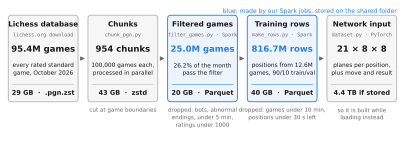

In [2]:
planes_bytes = total_rows * 21 * 64 * 4
cards = [  # (title, program, headline, detail, size on disk, note under the card)
    ("Lichess database", "lichess.org download", f"{millions(f['games_in'])} games",
     "every rated standard\ngame, October 2026", "29 GB  ·  .pgn.zst", ""),
    ("Chunks", "chunk_pgn.py", "954 chunks",
     "100,000 games each,\nprocessed in parallel", "43 GB  ·  zstd", "cut at game boundaries"),
    ("Filtered games", "filter_games.py · Spark", f"{millions(f['kept'])} games",
     f"{f['kept'] / f['games_in']:.1%} of the month\npass the filter", "20 GB  ·  Parquet",
     "dropped: bots, abnormal\nendings, under 5 min,\nratings under 1000"),
    ("Training rows", "make_rows.py · Spark", f"{millions(total_rows)} rows",
     f"positions from {millions(seen['kept'])}\ngames, 90/10 train/val", "40 GB  ·  Parquet",
     "dropped: games under 10 min,\npositions under 30 s left"),
    ("Network input", "dataset.py · PyTorch", "21 × 8 × 8",
     "planes per position,\nplus move and result", f"{planes_bytes / 1e12:.1f} TB if stored",
     "so it is built while\nloading instead"),
]
step, w, h, y = 1.45, 1.27, 1.5, 0.66
fig, ax = plt.subplots(figsize=(WIDE, 2.4))
ax.set_xlim(-0.02, (len(cards) - 1) * step + w + 0.02), ax.set_ylim(0, 2.3), ax.axis("off")
for i, (title, prog, headline, detail, size, note) in enumerate(cards):
    x, top = i * step, y + h
    ours = i in (2, 3)
    edge = BLUE if ours else GRAY
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.06",
                                fc="#eef4fc" if ours else "#f6f6f6", ec=edge, lw=0.9))
    ax.text(x + w / 2, top - 0.1, title, ha="center", va="top", fontsize=7.2, weight="bold", color=TEXT)
    ax.text(x + w / 2, top - 0.3, prog, ha="center", va="top", fontsize=5.0, family="monospace", color=TEXT2)
    ax.text(x + w / 2, top - 0.52, headline, ha="center", va="top", fontsize=8.5, weight="bold",
            color=BLUE if ours else TEXT)
    ax.text(x + w / 2, top - 0.8, detail, ha="center", va="top", fontsize=5.8, color=TEXT, linespacing=1.35)
    ax.plot([x + 0.08, x + w - 0.08], [y + 0.3, y + 0.3], color=edge, lw=0.5)
    ax.text(x + w / 2, y + 0.15, size, ha="center", va="center", fontsize=6.5, weight="bold", color=TEXT)
    ax.text(x + w / 2, y - 0.08, note, ha="center", va="top", fontsize=5.6, color=TEXT2, linespacing=1.35)
    if i:
        ax.add_patch(FancyArrowPatch((x - step + w + 0.02, y + h / 2), (x - 0.02, y + h / 2),
                                     arrowstyle="-|>", mutation_scale=8, color=TEXT2, lw=0.9))
ax.text((len(cards) - 1) * step + w, 2.28, "blue: made by our Spark jobs, stored on the shared folder",
        fontsize=6, color=BLUE, va="top", ha="right")
save(fig, "pipeline")
plt.show()

## 2. From one position to a training example

What a single training example is: (1) a position from a kept game and the move the human played, (2) the row
`make_rows.py` stores for it, and (3) the tensors `dataset.py` builds from that row. The game is an
illustrative four-move mate, not one from the data. We show a Black-to-move position because it also shows
the board being flipped to the side to move's view.

saved figures/pipeline/example.svg and .pdf


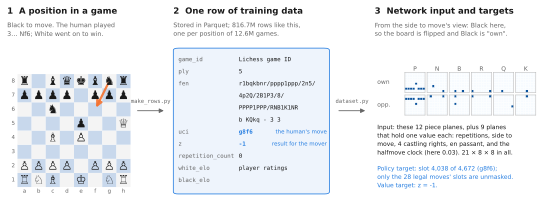

In [3]:
EXAMPLE = ["e2e4", "e7e5", "f1c4", "b8c6", "d1h5", "g8f6", "h5f7"]  # 1. e4 e5 2. Bc4 Nc6 3. Qh5 Nf6 4. Qxf7# 1-0
ROW = 5                                                            # the position before 3... Nf6

board, sans = chess.Board(), []
for ply, uci in enumerate(EXAMPLE):
    move = chess.Move.from_uci(uci)
    if ply == ROW:
        pos, played = board.copy(), move
    sans.append(board.san(move))
    board.push(move)
planes = board_to_planes(pos, repetition_count=0)
policy_index = move_to_index(played, pos)
n_legal = pos.legal_moves.count()
z = -1  # White won and Black is to move


def header(x, number, title, subtitle):
    fig.text(x, 0.95, f"{number}  {title}", fontsize=8.5, weight="bold", color=TEXT, va="top")
    fig.text(x, 0.885, subtitle, fontsize=6.3, color=TEXT2, va="top", linespacing=1.35)


def arrow(x0, x1, label):
    fig.add_artist(FancyArrowPatch((x0, 0.47), (x1, 0.47), transform=fig.transFigure,
                                   arrowstyle="-|>", mutation_scale=9, color=TEXT2, lw=0.9))
    fig.text((x0 + x1) / 2, 0.50, label, ha="center", va="bottom", fontsize=5.5, family="monospace", color=TEXT2)


fig = plt.figure(figsize=(WIDE, 3.0))

# (1) the position, with the move played
header(0.0, "1", "A position in a game", f"Black to move. The human played\n3… {sans[ROW]}; White went on to win.")
ax = fig.add_axes([0.005, 0.08, 0.24, 0.24 * WIDE / 3.0])
for sq in chess.SQUARES:
    fl, rk = chess.square_file(sq), chess.square_rank(sq)
    ax.add_patch(Rectangle((fl, rk), 1, 1, color="#c8d8ec" if (fl + rk) % 2 == 0 else "#f4f4f4", lw=0))
    piece = pos.piece_at(sq)
    if piece:
        ax.text(fl + 0.5, rk + 0.45, piece.unicode_symbol(), ha="center", va="center", fontsize=12, color=TEXT)
for i in range(8):
    ax.text(i + 0.5, -0.3, "abcdefgh"[i], ha="center", va="center", fontsize=5.5, color=TEXT2)
    ax.text(-0.3, i + 0.5, str(i + 1), ha="center", va="center", fontsize=5.5, color=TEXT2)
f0, f1 = played.from_square, played.to_square
ax.add_patch(FancyArrowPatch((chess.square_file(f0) + 0.5, chess.square_rank(f0) + 0.5),
                             (chess.square_file(f1) + 0.5, chess.square_rank(f1) + 0.5),
                             arrowstyle="-|>", mutation_scale=12, color=ORANGE, lw=2.2, alpha=0.9))
ax.set_xlim(-0.55, 8), ax.set_ylim(-0.55, 8), ax.set_aspect("equal"), ax.axis("off")

arrow(0.255, 0.315, "make_rows.py")

# (2) the stored row
header(0.33, "2", "One row of training data", f"Stored in Parquet; {millions(total_rows)} rows like this,\none per position of {millions(seen['kept'])} games.")
board_fen, rest = pos.fen().split(" ", 1)
ranks = board_fen.split("/")
card = [
    ("game_id", "Lichess game ID", None),
    ("ply", str(ROW), None),
    ("fen", "/".join(ranks[:3]) + "/", None),
    ("", "/".join(ranks[3:6]) + "/", None),
    ("", "/".join(ranks[6:]), None),
    ("", rest, None),
    ("uci", played.uci(), "the human's move"),
    ("z", f"{z:+d}", "result for the mover"),
    ("repetition_count", "0", None),
    ("white_elo", "player ratings", None),
    ("black_elo", "", None),
]
cx, cy, lh = 0.335, 0.72, 0.056
fig.add_artist(FancyBboxPatch((cx - 0.005, cy - lh * len(card) - 0.02), 0.31, lh * len(card) + 0.06,
                              boxstyle="round,pad=0,rounding_size=0.01", transform=fig.transFigure,
                              fc="#eef4fc", ec=BLUE, lw=0.8))
for i, (key, value, note) in enumerate(card):
    yy = cy - i * lh
    highlight = key in ("uci", "z")
    fig.text(cx + 0.005, yy, key, fontsize=5.8, family="monospace", color=TEXT2, va="top")
    fig.text(cx + 0.125, yy, value, fontsize=5.8, family="monospace", va="top",
             color=BLUE if highlight else TEXT, weight="bold" if highlight else "normal")
    if note:
        fig.text(cx + 0.30, yy, note, fontsize=5.5, color=BLUE, va="top", ha="right")

arrow(0.655, 0.715, "dataset.py")

# (3) the tensors
header(0.73, "3", "Network input and targets", "From the side to move's view: Black here,\nso the board is flipped and Black is \"own\".")
gx, gy, gw, gap = 0.735, 0.555, 0.040, 0.004
gh = gw * WIDE / 3.0
for k in range(12):
    row, colm = divmod(k, 6)
    a = fig.add_axes([gx + 0.055 + colm * (gw + gap), gy - row * (gh + 0.012), gw, gh])
    a.pcolormesh(planes[k], cmap="Blues", vmin=0, vmax=1.15, edgecolors="white", linewidth=0.3)  # vector squares, rank 0 at the bottom
    a.set_aspect("equal"), a.set_xlim(0, 8), a.set_ylim(0, 8)
    a.set_xticks([]), a.set_yticks([]), a.grid(False)
    for sp in a.spines.values():
        sp.set_visible(True), sp.set_color(GRAY), sp.set_linewidth(0.5)
    if row == 0:
        a.set_title("PNBRQK"[colm], fontsize=6, color=TEXT2, pad=1.5)
fig.text(gx, gy + gh / 2, "own", fontsize=6, color=TEXT2, va="center")
fig.text(gx, gy - gh - 0.012 + gh / 2, "opp.", fontsize=6, color=TEXT2, va="center")
state = planes[12:].reshape(9, -1).max(axis=1)
fig.text(gx, gy - gh - 0.05,
         "Input: these 12 piece planes, plus 9 planes\n"
         f"that hold one value each: repetitions, side to\n"
         f"move, 4 castling rights, en passant, and the\n"
         f"halfmove clock (here {state[8]:.2f}). 21 × 8 × 8 in all.",
         fontsize=6, color=TEXT, va="top", linespacing=1.4)
fig.text(gx, 0.22,
         f"Policy target: slot {policy_index:,} of 4,672 ({played.uci()});\n"
         f"only the {n_legal} legal moves' slots are unmasked.\n"
         f"Value target: z = {z:+d}.",
         fontsize=6, color=BLUE, va="top", linespacing=1.4)
save(fig, "example")
plt.show()

## 3. What the filter dropped

Each game is counted under the first rule it fails, in the order the filter checks them. The kept games are
split by whether `make_rows.py` used them (base time of 10 minutes or more, decision #11).

saved figures/pipeline/filter.svg and .pdf


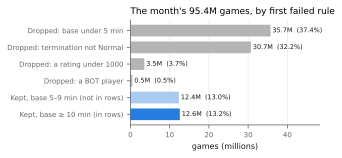

In [4]:
bars = [  # (label, count, colour), top to bottom
    ("Dropped: base under 5 min", f["short_time"], GRAY),
    ("Dropped: termination not Normal", f["not_normal_termination"], GRAY),
    ("Dropped: a rating under 1000", f["low_rating"], GRAY),
    ("Dropped: a BOT player", f["bot"], GRAY),
    ("Kept, base 5–9 min (not in rows)", seen["short_time_control"], LIGHT_BLUE),
    ("Kept, base ≥ 10 min (in rows)", seen["kept"] + seen["no_moves"], BLUE),
]
fig, ax = plt.subplots(figsize=(COL, 1.9))
ys = np.arange(len(bars))[::-1]
ax.barh(ys, [b[1] / 1e6 for b in bars], color=[b[2] for b in bars], height=0.7)
for yy, (_, n, _) in zip(ys, bars):
    ax.text(n / 1e6 + 0.5, yy, f"{millions(n)}  ({n / f['games_in']:.1%})", va="center", fontsize=6.5, color=TEXT)
ax.set_yticks(ys, [b[0] for b in bars])
ax.set_xlabel("games (millions)")
ax.set_xlim(0, max(b[1] for b in bars) / 1e6 * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title(f"The month's {millions(f['games_in'])} games, by first failed rule", loc="left")
save(fig, "filter")
plt.show()

## 4. Time controls

The most common time controls among the filtered games, coloured by whether they go into the rows.

saved figures/pipeline/time_controls.svg and .pdf


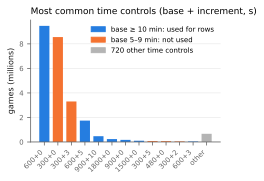

In [5]:
TOP = 12
min_base = s["rows_min_base_seconds"]
tcs = list(games["time_controls"].items())
labels = [t for t, _ in tcs[:TOP]] + ["other"]
counts = [n for _, n in tcs[:TOP]] + [sum(n for _, n in tcs[TOP:])]
colours = [BLUE if int(t.split("+")[0]) >= min_base else ORANGE for t, _ in tcs[:TOP]] + [GRAY]
fig, ax = plt.subplots(figsize=(COL, 2.2))
xs = np.arange(len(labels))
ax.bar(xs, np.array(counts) / 1e6, color=colours, width=0.75)
ax.set_xticks(xs, labels, rotation=45, ha="right")
ax.set_ylabel("games (millions)")
ax.grid(axis="x", visible=False)
ax.set_title("Most common time controls (base + increment, s)", loc="left")
ax.legend(handles=[Patch(color=BLUE, label=f"base ≥ {min_base // 60} min: used for rows"),
                   Patch(color=ORANGE, label="base 5–9 min: not used"),
                   Patch(color=GRAY, label=f"{len(tcs) - TOP} other time controls")], loc="upper right")
save(fig, "time_controls")
plt.show()

## 5. Player ratings

Average rating of the two players. The 10+ minute games (used) and the 5–9 minute games (not used) have
almost the same distribution, so leaving out the shorter games doesn't change the skill level of the data.

saved figures/pipeline/ratings.svg and .pdf


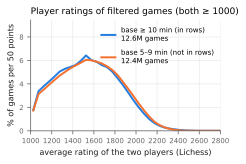

In [6]:
bins = np.array(games["rating_bins"])
centres = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(COL, 2.0))
for key, colour, label in (("in_rows", BLUE, "base ≥ 10 min (in rows)"),
                           ("not_in_rows", ORANGE, "base 5–9 min (not in rows)")):
    hist = np.array(games[key]["mean_rating_hist"])
    ax.plot(centres, hist / hist.sum() * 100, color=colour, lw=2,
            label=f"{label}\n{millions(games[key]['games'])} games")
ax.set_xlabel("average rating of the two players (Lichess)")
ax.set_ylabel("% of games per 50 points")
ax.set_xlim(1000, 2800)
ax.set_ylim(0, ax.get_ylim()[1] * 1.4)
ax.legend(loc="upper right", labelspacing=0.8)
ax.set_title("Player ratings of filtered games (both ≥ 1000)", loc="left")
save(fig, "ratings")
plt.show()

## 6. Results by rating

How games used for rows ended, by the players' average rating. This is the balance of the value target z.
Draws are rare (under 5% overall) but become more common with rating. Bins with fewer than 2,000 games are left
out.

saved figures/pipeline/results_by_rating.svg and .pdf


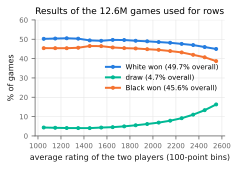

In [7]:
rb = games["in_rows"]["results_by_rating"]
edges = np.array(games["result_rating_bins"])
centres = (edges[:-1] + edges[1:]) / 2
total = np.sum([rb[k] for k in RESULT_STYLE], axis=0)
keep = total >= 2000
fig, ax = plt.subplots(figsize=(COL, 2.1))
for res, (colour, label) in RESULT_STYLE.items():
    share = np.array(rb[res]) / np.maximum(total, 1) * 100
    overall = sum(rb[res]) / total.sum() * 100
    ax.plot(centres[keep], share[keep], color=colour, lw=2, marker="o", ms=3, label=f"{label} ({overall:.1f}% overall)")
ax.set_xlabel("average rating of the two players (100-point bins)")
ax.set_ylabel("% of games")
ax.set_ylim(0, 60)
ax.legend(loc="center right")
ax.set_title(f"Results of the {millions(games['in_rows']['games'])} games used for rows", loc="left")
save(fig, "results_by_rating")
plt.show()

## 7. Rows per game

Training rows per game in the validation split: positions kept after the low-clock rule, which is almost the
game length in plies. The left plot is all games; the right plot splits them by result, in bins of 4 rows to
smooth out an odd/even pattern (a decisive game usually ends on the winner's move).

saved figures/pipeline/game_length.svg and .pdf


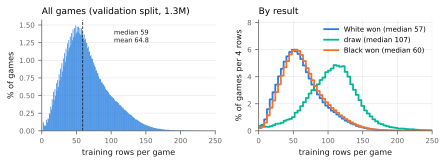

In [8]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(WIDE, 2.0), gridspec_kw={"wspace": 0.25})
hist = np.array(v["rows_per_game_hist"])
ax.bar(np.arange(1, len(hist) - 1), hist[1:-1] / v["games"] * 100, width=1.0, color=BLUE, lw=0)
med = v["rows_per_game_median"]
ax.axvline(med, color=TEXT, lw=0.8, ls="--")
ax.text(med + 45, ax.get_ylim()[1] * 0.92, f"median {med:.0f}\nmean {v['rows_per_game_mean']:.1f}",
        fontsize=6.5, color=TEXT, va="top")
ax.set_xlim(0, 250)
ax.set_xlabel("training rows per game")
ax.set_ylabel("% of games")
ax.grid(axis="x", visible=False)
ax.set_title(f"All games (validation split, {millions(v['games'])})", loc="left")

B = 4
for res, (colour, label) in RESULT_STYLE.items():
    h = np.array(v["rows_per_game_hist_by_result"][res][:-1])
    n = h.sum()
    binned = h[: len(h) // B * B].reshape(-1, B).sum(axis=1) / n * 100
    median = np.searchsorted(np.cumsum(h), n / 2)
    ax2.step(np.arange(len(binned)) * B, binned, where="post", color=colour, lw=1.8,
             label=f"{label} (median {median})")
ax2.set_xlim(0, 250)
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.3)
ax2.set_xlabel("training rows per game")
ax2.set_ylabel(f"% of games per {B} rows")
ax2.legend(loc="upper right")
ax2.set_title("By result", loc="left")
save(fig, "game_length")
plt.show()

## 8. Where in the game the rows come from

Share of rows at each ply. Every game contributes its opening, so early plies dominate.

saved figures/pipeline/rows_by_ply.svg and .pdf


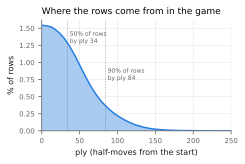

In [9]:
share = np.array(v["rows_by_ply"][:-1]) / v["rows"] * 100
fig, ax = plt.subplots(figsize=(COL, 2.0))
ax.fill_between(np.arange(len(share)), share, color=LIGHT_BLUE, lw=0)
ax.plot(np.arange(len(share)), share, color=BLUE, lw=1.5)
cum = np.cumsum(share)
for q in (50, 90):
    p = int(np.searchsorted(cum, q))
    ax.axvline(p, color=TEXT2, lw=0.6, ls=":")
    ax.text(p + 3, share.max() * (0.95 if q == 50 else 0.6), f"{q}% of rows\nby ply {p}", fontsize=6, color=TEXT2, va="top")
ax.set_xlim(0, 250)
ax.set_ylim(bottom=0)
ax.set_xlabel("ply (half-moves from the start)")
ax.set_ylabel("% of rows")
ax.set_title("Where the rows come from in the game", loc="left")
save(fig, "rows_by_ply")
plt.show()

## 9. Table of counts

A LaTeX table (needs `\usepackage{booktabs}`) with every count from the month down to train and validation.

In [10]:
zc = v["z_counts"]
nz = sum(zc.values())
lines = [
    ("Games in the month", f["games_in"]),
    (r"\quad dropped: base time under 5 min", f["short_time"]),
    (r"\quad dropped: termination not Normal", f["not_normal_termination"]),
    (r"\quad dropped: a rating under 1000", f["low_rating"]),
    (r"\quad dropped: a BOT player", f["bot"]),
    ("Games kept by the filter", f["kept"]),
    (r"\quad base 5--9 min (not used for rows)", seen["short_time_control"]),
    (r"\quad no moves", seen["no_moves"]),
    ("Games used for rows", seen["kept"]),
    ("Positions skipped: mover under 30 s", seen["low_clock_positions"]),
    ("Rows (positions)", total_rows),
    (rf"\quad train ({r['train']['games']:,} games)", r["train"]["rows"]),
    (rf"\quad validation ({r['val']['games']:,} games)", r["val"]["rows"]),
    ("Games in both splits", r["games_in_both_splits"]),
]
body = "\n".join(f"{name} & {n:,} \\\\" for name, n in lines)
tex = (f"% Generated by analysis/pipeline_figures.ipynb from results/data_stats_{MONTH}.json\n"
       "\\begin{tabular}{lr}\n\\toprule\nStage & Count \\\\\n\\midrule\n" + body + "\n\\midrule\n"
       f"Value targets z (validation rows): win / draw / loss & "
       f"{zc.get('1', 0) / nz:.1%} / {zc.get('0', 0) / nz:.1%} / {zc.get('-1', 0) / nz:.1%} \\\\\n"
       "\\bottomrule\n\\end{tabular}\n").replace("%", r"\%").replace(r"\% Generated", "% Generated")
(OUT / "pipeline_counts.tex").write_text(tex)
print(tex)

% Generated by analysis/pipeline_figures.ipynb from results/data_stats_2026-10.json
\begin{tabular}{lr}
\toprule
Stage & Count \\
\midrule
Games in the month & 95,395,628 \\
\quad dropped: base time under 5 min & 35,701,703 \\
\quad dropped: termination not Normal & 30,700,571 \\
\quad dropped: a rating under 1000 & 3,546,921 \\
\quad dropped: a BOT player & 494,406 \\
Games kept by the filter & 24,952,027 \\
\quad base 5--9 min (not used for rows) & 12,355,596 \\
\quad no moves & 1,725 \\
Games used for rows & 12,594,706 \\
Positions skipped: mover under 30 s & 5,359,898 \\
Rows (positions) & 816,677,133 \\
\quad train (11,335,375 games) & 735,064,499 \\
\quad validation (1,259,331 games) & 81,612,634 \\
Games in both splits & 0 \\
\midrule
Value targets z (validation rows): win / draw / loss & 46.4\% / 7.8\% / 45.8\% \\
\bottomrule
\end{tabular}

